# Linear Regression – Complete End-to-End Project
## Scikit-learn Diabetes Dataset

**Objective:** Build and evaluate OLS Linear Regression, Ridge, Lasso and ElasticNet models. Examine assumptions, multicollinearity, scaling, bias–variance considerations and cross-validation.

**Reproducibility:** 80/20 train-test split with `random_state=42`. Hyperparameters are selected using 5-fold cross-validation on the training set only.

# PART A – THEORY

## Section 1 – Fundamentals

1. **Linear Regression:** A supervised learning method that models the relationship between one continuous target and one or more input features using a linear combination of the features.
2. **General equation:**
   \[
   y_i = \beta_0 + \beta_1x_{i1}+\beta_2x_{i2}+\cdots+\beta_px_{ip}+\epsilon_i
   \]
   Here, \(\beta_0\) is the intercept, \(\beta_j\) are coefficients and \(\epsilon_i\) is the error.
3. **OLS objective:** Ordinary Least Squares chooses coefficients that minimize the sum of squared residuals:
   \[
   \min_{\beta_0,\ldots,\beta_p}\sum_{i=1}^{n}(y_i-\hat y_i)^2
   \]
4. **Residual:** The difference between an observed target and its predicted value, \(e_i=y_i-\hat y_i\).
5. **R² score:** The proportion of target variation explained by the model relative to predicting the target mean. It can be negative on unseen data when predictions are worse than that baseline.

## Section 2 – Linear Regression Assumptions

1. **Linearity:** The expected target is a linear function of the predictors and coefficients.
2. **Independence of errors:** Error terms are not correlated across observations.
3. **Homoscedasticity:** Error variance is approximately constant across fitted values or predictor levels.
4. **Normality of residuals:** For classical small-sample inference, residuals/errors are approximately normally distributed. This is not required for OLS coefficients to be computed.
5. **No multicollinearity:** Predictors should not have severe linear dependencies. Perfect multicollinearity prevents unique coefficient estimation; high multicollinearity makes coefficients unstable.
6. **If assumptions are violated:** Coefficients may be unstable or misleading, standard errors and inferential tests may be unreliable, or predictions may systematically miss nonlinear patterns. The impact depends on which assumption is violated.

## Section 3 – Regularization and Bias–Variance

1. **Bias:** Error from overly simple assumptions in the model. **Variance:** Sensitivity of the fitted model to changes in the training sample.
2. **Underfitting:** Model is too simple and performs poorly on both training and test data. **Overfitting:** Model captures noise in training data and performs worse on unseen data.
3. **Regularized objectives** (intercept is typically not penalized):
   - Ridge:
     \[
     \min_{\beta}\left[\sum_i(y_i-\hat y_i)^2+\alpha\sum_j\beta_j^2\right]
     \]
   - Lasso:
     \[
     \min_{\beta}\left[\sum_i(y_i-\hat y_i)^2+\alpha\sum_j|\beta_j|\right]
     \]
   - ElasticNet:
     \[
     \min_{\beta}\left[\sum_i(y_i-\hat y_i)^2+\alpha\left(r\sum_j|\beta_j|+\frac{1-r}{2}\sum_j\beta_j^2\right)\right]
     \]
     where \(r\) is `l1_ratio`.
4. **Ridge vs Lasso:** Ridge uses an L2 penalty and generally shrinks coefficients toward zero without setting many exactly to zero. Lasso uses an L1 penalty and can set some coefficients exactly to zero, performing feature selection.
5. **Why scale features?** Penalties act on coefficient magnitudes. If predictors use very different units, the penalty can affect them unevenly. Standardization puts predictors on comparable scales. Scaling is fitted on training data only to prevent leakage.

# PART B – PRACTICAL IMPLEMENTATION
## Step 1 – Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from scipy import stats

RANDOM_STATE = 42

## Step 2 – Load Dataset

In [2]:
# Load the built-in Scikit-learn Diabetes dataset and convert it to a DataFrame.
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()

display(df.head())
print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

X = df.drop(columns="target")
y = df["target"]
print("\\nFeature columns:", X.columns.tolist())
print("Target column: target")

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Shape: (442, 11)
\nData types:


,dtype
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64


\nMissing values:


,missing_count
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


\nFeature columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target column: target


The dataset contains 442 observations, 10 numeric predictor features and one continuous target. The target is a quantitative measure of disease progression one year after baseline. The built-in dataset is complete, so no missing-value imputation is needed here.

## Step 3 – Exploratory Data Analysis

In [3]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


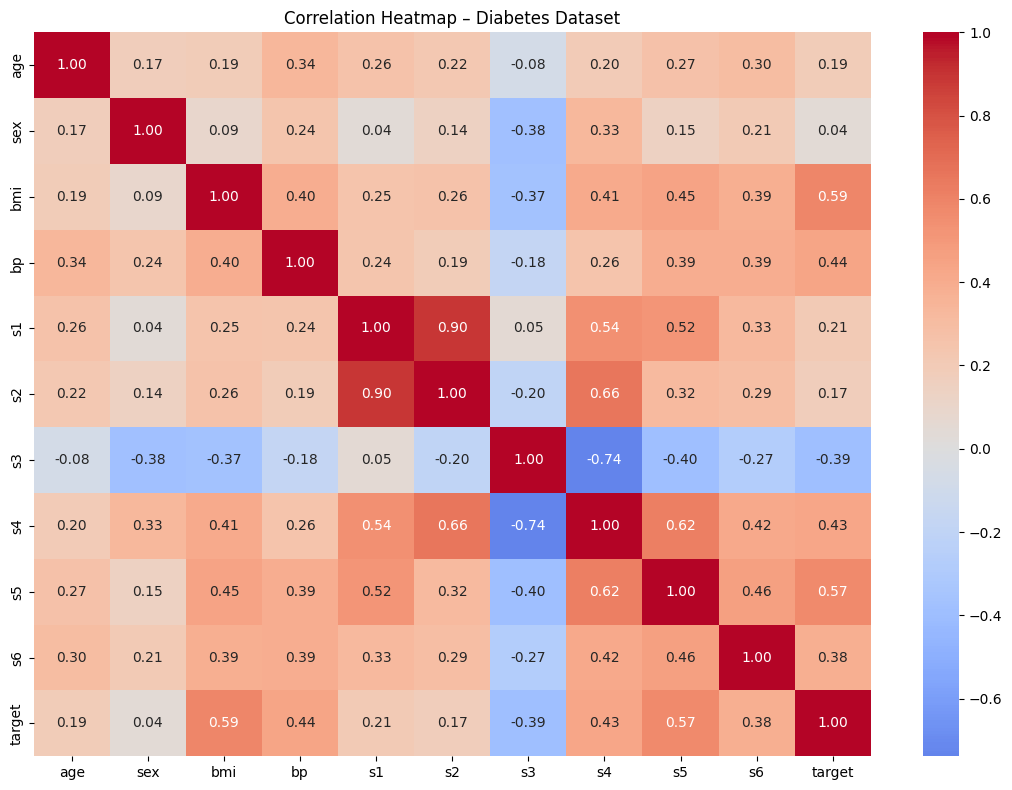

In [4]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap – Diabetes Dataset")
plt.tight_layout()
plt.show()

In [5]:
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = [
    (col, row, upper.loc[row, col])
    for col in upper.columns
    for row in upper.index
    if pd.notna(upper.loc[row, col]) and upper.loc[row, col] >= 0.70
]
print("Feature pairs with absolute correlation >= 0.70:")
print(high_corr_pairs if high_corr_pairs else "None at this threshold.")

Feature pairs with absolute correlation >= 0.70:
[('s2', 's1', np.float64(0.8966629578104894)), ('s4', 's3', np.float64(0.7384927292583823))]


### EDA observations

- Correlation indicates linear association, not causation.
- Highly correlated predictor pairs can indicate multicollinearity.
- The `s1`, `s2`, `s3` and `s4` measurements are strongly interrelated in this dataset; the exact values are shown in the heatmap and printed pair list.
- The target correlations can help describe linear associations, but they do not by themselves establish predictive usefulness.

## Step 4 – Train-Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (353, 10)
X_test: (89, 10)
y_train: (353,)
y_test: (89,)


## Step 5 – Feature Scaling

In [7]:
# StandardScaler learns the mean and standard deviation from training data only.
# The fitted scaler is then applied to test data without refitting.
# This avoids data leakage and makes regularization penalties comparable across features.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (353, 10)
Scaled test shape: (89, 10)


For model development, scaling is also embedded in each Pipeline below. This is especially important for Ridge, Lasso and ElasticNet. Pipelines ensure that scaling is refitted inside each cross-validation fold using only that fold's training portion.

## Step 6 – OLS Linear Regression

In [8]:
ols_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
ols_model.fit(X_train, y_train)

def evaluate_regression(estimator, X_train, y_train, X_test, y_test):
    train_pred = estimator.predict(X_train)
    test_pred = estimator.predict(X_test)
    return {
        "Train R²": r2_score(y_train, train_pred),
        "Test R²": r2_score(y_test, test_pred),
        "MSE": mean_squared_error(y_test, test_pred),
        "RMSE": mean_squared_error(y_test, test_pred) ** 0.5
    }

ols_metrics = evaluate_regression(ols_model, X_train, y_train, X_test, y_test)
display(pd.Series(ols_metrics, name="OLS").to_frame())

,OLS
Train R²,0.527919
Test R²,0.452603
MSE,2900.193628
RMSE,53.853446


**Interpretation:** Compare training and test R². A large positive gap can suggest overfitting; similarly low scores can suggest underfitting or limited linear signal. MSE and RMSE are measured in squared target units and target units, respectively.

## Step 7 – Ridge Regression

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])
ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="r2",
    cv=cv
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_
print("Best Ridge parameters:", ridge_search.best_params_)
display(pd.DataFrame(ridge_search.cv_results_)[["param_model__alpha", "mean_test_score", "std_test_score"]])
print("Ridge metrics:", evaluate_regression(ridge_model, X_train, y_train, X_test, y_test))

Best Ridge parameters: {'model__alpha': 1}


,param_model__alpha,mean_test_score,std_test_score
0,0.01,0.480377,0.040877
1,0.10,0.480479,0.040801
2,1.00,0.480784,0.040422
3,10.00,0.479743,0.038925
4,100.00,0.470375,0.025187


Ridge metrics: {'Train R²': 0.5276319768458047, 'Test R²': 0.45414652070698214, 'MSE': 2892.0145657501735, 'RMSE': 53.7774540653439}


Ridge penalizes large coefficients and usually shrinks them toward zero. It is particularly useful when predictors are correlated because it can reduce coefficient instability. The chosen alpha is the best mean cross-validation R² among the tested values.

## Step 8 – Lasso Regression

In [10]:
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=50000))
])
lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10]},
    scoring="r2",
    cv=cv
)
lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_
print("Best Lasso parameters:", lasso_search.best_params_)
lasso_coefficients = pd.Series(
    lasso_model.named_steps["model"].coef_,
    index=X.columns,
    name="Lasso coefficient"
)
display(lasso_coefficients.to_frame())
print("Features with zero coefficients:", lasso_coefficients[lasso_coefficients == 0].index.tolist())
print("Lasso metrics:", evaluate_regression(lasso_model, X_train, y_train, X_test, y_test))

Best Lasso parameters: {'model__alpha': 0.1}


,Lasso coefficient
age,1.730451
sex,-11.316359
bmi,25.824627
bp,16.644252
s1,-29.358412
s2,13.275844
s3,0.547948
s4,10.236168
s5,29.632826
s6,2.393475


Features with zero coefficients: []
Lasso metrics: {'Train R²': 0.5272214154674504, 'Test R²': 0.455541399027904, 'MSE': 2884.624288735213, 'RMSE': 53.708698445737944}


Lasso can produce exact zero coefficients, effectively removing predictors from the model. Whether it selects any zero coefficients depends on the chosen alpha and the data; inspect the output rather than assuming that it must remove a feature.

## Step 9 – ElasticNet

In [11]:
elastic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(max_iter=50000))
])
elastic_search = GridSearchCV(
    elastic_pipeline,
    param_grid={
        "model__alpha": [0.001, 0.01, 0.1, 1, 10],
        "model__l1_ratio": [0.2, 0.5, 0.8]
    },
    scoring="r2",
    cv=cv
)
elastic_search.fit(X_train, y_train)
elastic_model = elastic_search.best_estimator_
print("Best ElasticNet parameters:", elastic_search.best_params_)
print("ElasticNet metrics:", evaluate_regression(elastic_model, X_train, y_train, X_test, y_test))

Best ElasticNet parameters: {'model__alpha': 0.01, 'model__l1_ratio': 0.8}
ElasticNet metrics: {'Train R²': 0.5277070037242579, 'Test R²': 0.454011202261828, 'MSE': 2892.731503406973, 'RMSE': 53.784119435080214}


ElasticNet combines L1 and L2 penalties. `l1_ratio` controls the mix: values closer to 1 emphasize Lasso, while values closer to 0 emphasize Ridge. The grid search tests the supplied combinations using training-set cross-validation.

## Step 10 – Model Comparison

In [12]:
models = {
    "OLS Linear Regression": ols_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model,
    "ElasticNet": elastic_model
}
comparison_rows = []
for name, estimator in models.items():
    comparison_rows.append({"Model": name, **evaluate_regression(estimator, X_train, y_train, X_test, y_test)})
comparison_df = pd.DataFrame(comparison_rows).sort_values("Test R²", ascending=False)
display(comparison_df)
best_model_name = comparison_df.iloc[0]["Model"]
print("Best model by test R² in this split:", best_model_name)

,Model,Train R²,Test R²,MSE,RMSE
2,Lasso,0.527221,0.455541,2884.624289,53.708698
1,Ridge,0.527632,0.454147,2892.014566,53.777454
3,ElasticNet,0.527707,0.454011,2892.731503,53.784119
0,OLS Linear Regression,0.527919,0.452603,2900.193628,53.853446


Best model by test R² in this split: Lasso


The best model is identified by the highest test R² in this single held-out split. Also consider MSE/RMSE and cross-validation stability; a tiny difference in test performance does not necessarily imply a meaningful practical advantage.

## Step 11 – Assumption Checking

The following diagnostic plots use residuals from the OLS model on the held-out test set. Visual checks are diagnostic indicators, not definitive statistical proof.

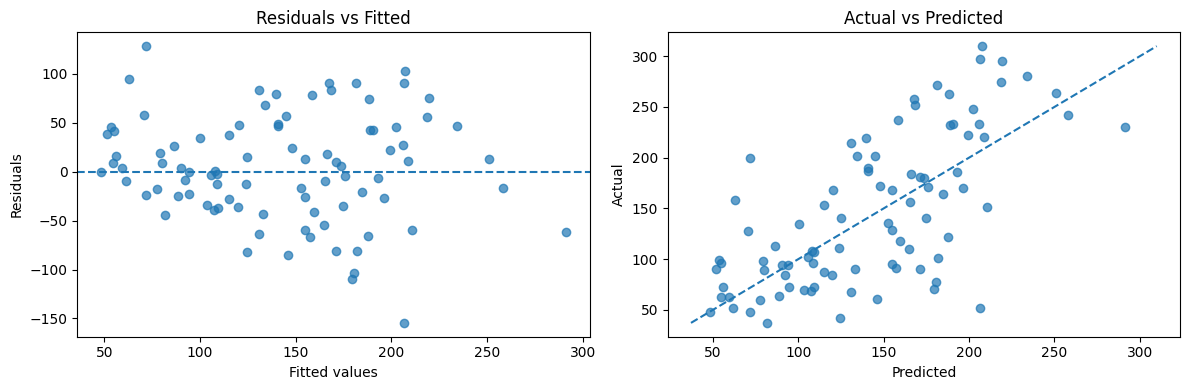

In [13]:
ols_test_pred = ols_model.predict(X_test)
ols_residuals = y_test - ols_test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(ols_test_pred, ols_residuals, alpha=0.7)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs Fitted")
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")

axes[1].scatter(ols_test_pred, y_test, alpha=0.7)
low = min(y_test.min(), ols_test_pred.min())
high = max(y_test.max(), ols_test_pred.max())
axes[1].plot([low, high], [low, high], linestyle="--")
axes[1].set_title("Actual vs Predicted")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

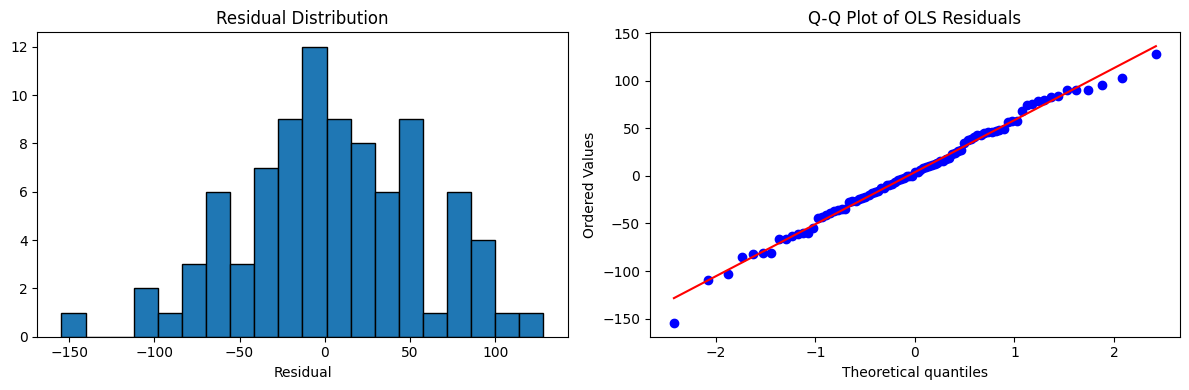

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(ols_residuals, bins=20, edgecolor="black")
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Residual")

stats.probplot(ols_residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot of OLS Residuals")
plt.tight_layout()
plt.show()

In [15]:
# VIF is calculated from training predictors. A constant is added for the auxiliary regressions.
X_vif = pd.DataFrame(
    StandardScaler().fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)
X_vif_const = add_constant(X_vif)
vif_table = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif_const.values, i + 1)
        for i in range(len(X_vif.columns))
    ]
}).sort_values("VIF", ascending=False)
display(vif_table)

,Feature,VIF
4,s1,55.252137
5,s2,35.759309
6,s3,14.285594
8,s5,10.071155
7,s4,9.333044
2,bmi,1.573561
9,s6,1.500654
3,bp,1.422084
1,sex,1.268854
0,age,1.217114


### Assumption-check observations

- **Linearity:** Inspect actual-versus-predicted and residual-versus-fitted plots. A random residual cloud around zero is more consistent with a linear specification; visible curves suggest possible nonlinearity.
- **Normality:** Inspect the histogram and Q-Q plot. Strong departures from the reference line suggest non-normal residuals.
- **Homoscedasticity:** In the residual-versus-fitted plot, the vertical spread should be roughly similar across fitted values. A funnel shape can indicate heteroscedasticity.
- **Multicollinearity:** VIF values quantify how strongly a predictor is explained by the other predictors. Values around 1 indicate little linear inflation; values above 5 (and especially above 10) are often treated as warning signs, though thresholds are rules of thumb.
- **Independence:** This dataset is not a time series, but row order alone does not prove independent sampling. Consider the data collection design when assessing independence.

## Step 12 – 5-Fold Cross Validation

In [16]:
cv_rows = []
for name, estimator in models.items():
    scores = cross_val_score(estimator, X_train, y_train, cv=cv, scoring="r2")
    cv_rows.append({
        "Model": name,
        "Mean CV R²": scores.mean(),
        "Std CV R²": scores.std(),
        "Test R²": r2_score(y_test, estimator.predict(X_test))
    })
cv_comparison = pd.DataFrame(cv_rows).sort_values("Mean CV R²", ascending=False)
display(cv_comparison)

,Model,Mean CV R²,Std CV R²,Test R²
2,Lasso,0.481195,0.039798,0.455541
3,ElasticNet,0.480791,0.040465,0.454011
1,Ridge,0.480784,0.040422,0.454147
0,OLS Linear Regression,0.480365,0.040886,0.452603


### Cross-validation interpretation

The mean 5-fold CV R² estimates performance across different training/validation partitions of the training set. Its standard deviation indicates how much the score varies across folds. Compare mean CV R² with held-out test R²: similar values suggest the test result is broadly consistent with CV; a large difference may indicate sampling variation or model-selection effects. A low standard deviation suggests more stable fold-to-fold performance.

## Final Conclusion

This project applied OLS, Ridge, Lasso and ElasticNet regression to the Scikit-learn Diabetes dataset. It demonstrated that standardization is important when using coefficient penalties, and that regularization can reduce coefficient magnitudes and help manage multicollinearity. The train/test comparison and residual diagnostics provide evidence about model fit and assumptions, while 5-fold cross-validation offers a more stable estimate than a single split. The best model should be selected by considering cross-validation performance, held-out test performance, error metrics and interpretability rather than one score alone.

## Optional – Save model results

In [17]:
import json
summary = {
    "dataset_shape": list(df.shape),
    "best_model_by_test_r2": best_model_name,
    "model_comparison": comparison_df.to_dict(orient="records"),
    "cross_validation": cv_comparison.to_dict(orient="records"),
    "ridge_best_params": ridge_search.best_params_,
    "lasso_best_params": lasso_search.best_params_,
    "elasticnet_best_params": elastic_search.best_params_
}
with open("linear_regression_results.json", "w") as file:
    json.dump(summary, file, indent=2)
print("Saved linear_regression_results.json")

Saved linear_regression_results.json
